# Predicting joint contact forces from gait inputs

Subjects: ACL-injured participants from an asymmetric walking study.

Joint contact forces are the resultant forces transmitted across a joint and reflect the combined effects of external loading and muscle forces. They are important determinants of the mechanical loading experienced by articular cartilage. Individuals who have undergone anterior cruciate ligament (ACL) reconstruction often exhibit altered knee joint loading during walking, which may contribute to their increased risk of post-traumatic knee osteoarthritis. Quantifying joint contact forces is therefore important for understanding changes in joint loading, monitoring rehabilitation, and evaluating interventions designed to improve walking mechanics.

Direct measurement of joint contact forces *in vivo* generally requires instrumented joint implants, which are not routinely available in clinical practice. Instead, these forces are estimated using musculoskeletal models implemented in software such as OpenSim. The process begins with gait laboratory measurements, including the positions of reflective markers attached to the body and ground reaction forces recorded during walking. A generic musculoskeletal model is scaled to the participant's anatomy, joint angles are estimated from marker trajectories, and muscle forces are estimated using the joint kinematics and external forces. These quantities are then used to calculate the resultant forces transmitted across the joints. Although widely used in biomechanics research, this computational pipeline can require hours to process walking data from multiple participants, limiting its potential for routine clinical use.

The goal of this project is to develop a Gaussian process (GP) emulator that predicts joint contact forces without repeating the computationally expensive OpenSim analysis. An emulator is a statistical model trained to approximate the outputs of a computational model. Here, OpenSim provides the training data by computing joint contact forces for a collection of recorded strides. The GP then learns the relationship between the measured gait characteristics and the corresponding OpenSim force estimates. Specifically, the inputs consist of three ground reaction force curves, five joint angle curves, treadmill belt speed, body mass, and height, while the outputs are the joint contact force curves at the hip, knee, and ankle. Because both the gait measurements and joint contact forces vary throughout the gait cycle, the emulator must learn a nonlinear relationship between multiple input curves and multiple output curves. A GP provides a flexible framework for modeling these relationships while accounting for dependence across gait time and quantifying uncertainty in its predictions. Once fitted, the emulator can estimate the joint contact force curves of a new stride without running OpenSim, potentially reducing computation from hours to seconds or less. With sufficient predictive accuracy and computational speed, this approach could enable joint loading assessments during clinical gait evaluations and support more timely adjustments to rehabilitation strategies following ACL reconstruction.

The data used to develop and evaluate the emulator consist of 620 right-leg strides collected from fifteen participants who had undergone ACL reconstruction. Each participant walked on an instrumented treadmill at belt speeds of 1.0, 1.25, and 1.5 m/s. For each stride, the input measurements were recorded and the corresponding joint contact forces were estimated using OpenSim. All input and output curves were normalized to 101 equally spaced points over the gait cycle, defined from one heel strike to the next. The data were divided by participant, with twelve participants assigned to training and three held out for testing. This participant-level split ensures that no strides from the test participants are used during model fitting, allowing predictive performance to be evaluated on individuals not represented in the training data. This evaluation is particularly important for assessing whether the emulator can generalize across individuals, a necessary condition for its eventual application to new patients.

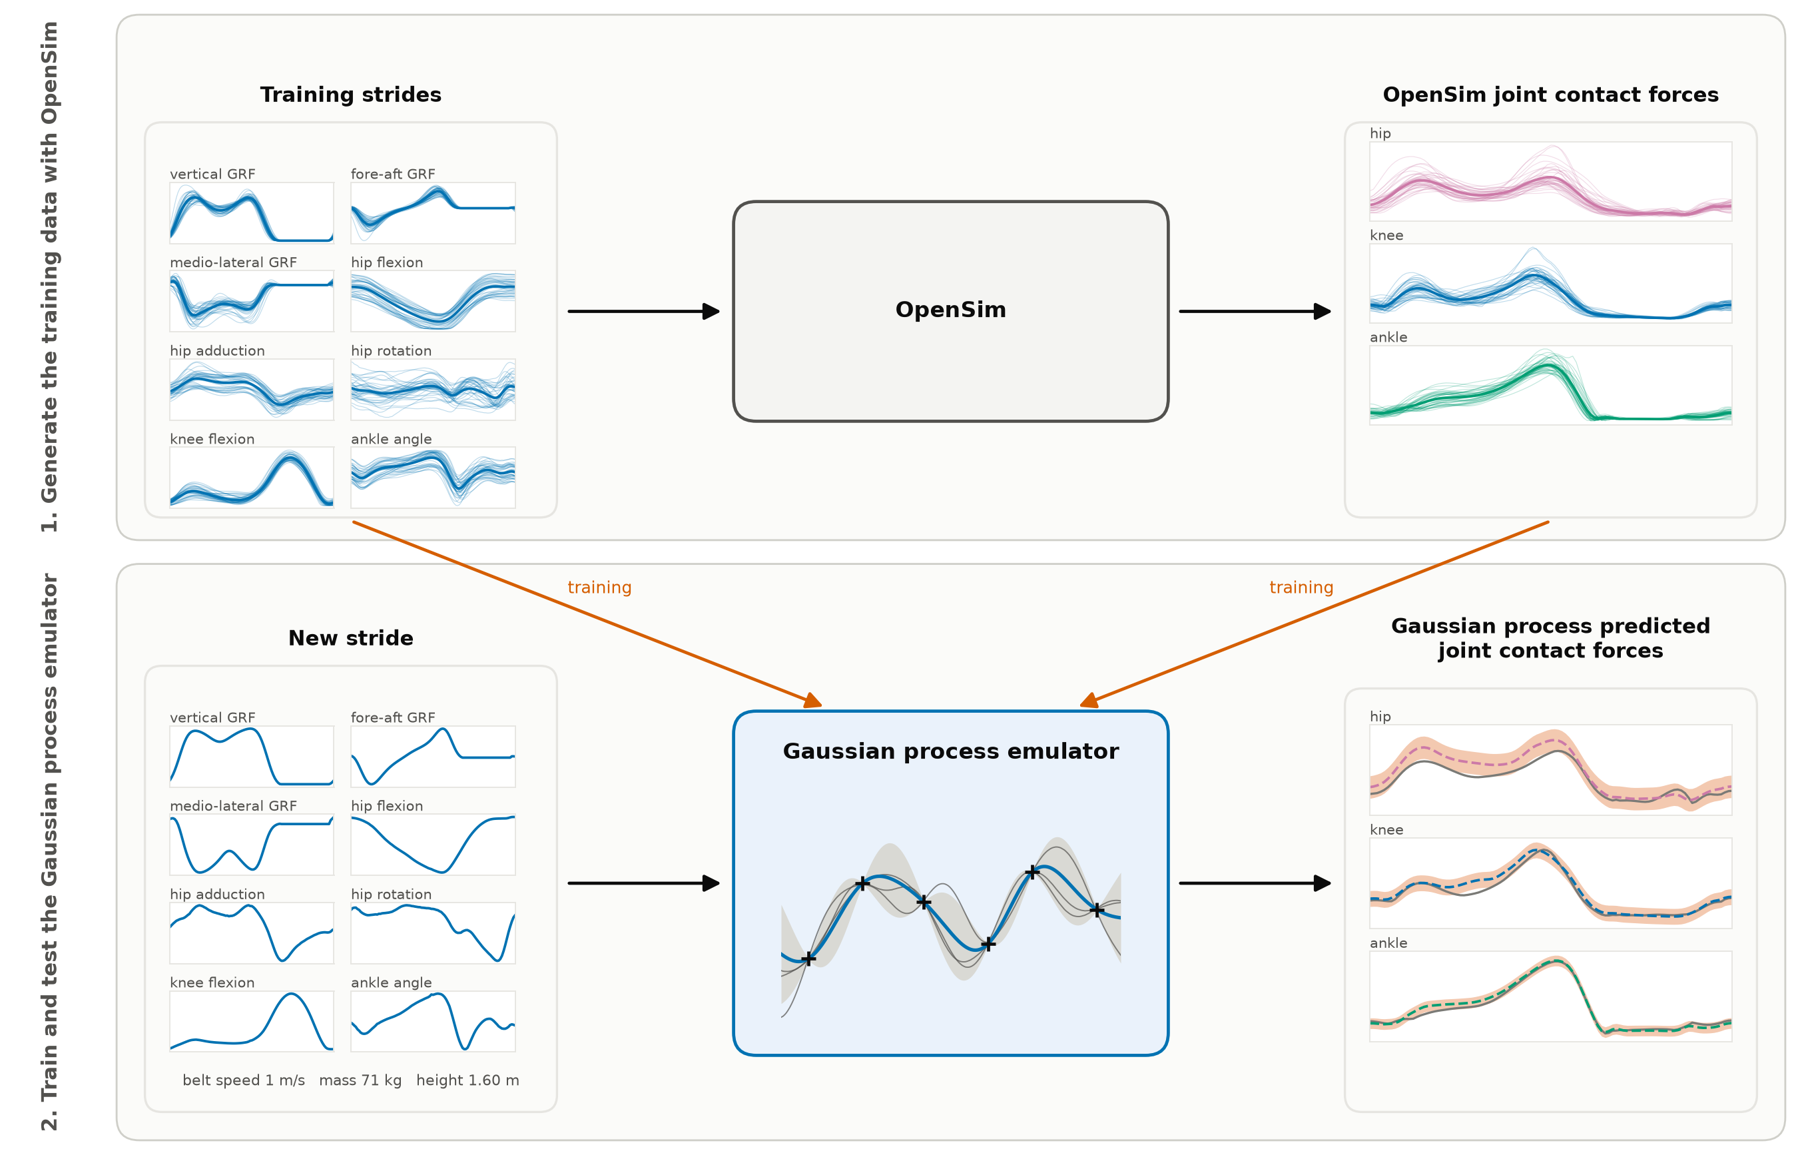


## Setup

Load the necessary libraries.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SPEED_COLOURS = {1.0: "#0072B2", 1.25: "#D55E00", 1.4: "#000000", 1.5: "#009E73"}
JOINT_COLOURS = {"hip": "#CC79A7", "knee": "#0072B2", "ankle": "#009E73"}

## Data

One row is one stride of the right leg. `x-*.csv` holds the inputs (three ground reaction force curves, five joint angle curves, belt speed, mass, height), `y-*.csv` the outputs (the hip, knee and ankle joint contact force curves from OpenSim). Each curve is sampled at 101 points of the gait cycle, 0 to 100 %, heel strike to heel strike. Row i of x and row i of y are the same stride.

In [ ]:
!gdown --folder "https://drive.google.com/drive/folders/1CI5OAxzB9qYI9vIxW1f0cGE4SN1hhyBj" -q

In [ ]:
print(open("data/log.txt").read())

In [ ]:
x_train = pd.read_csv("data/x-train.csv")
y_train = pd.read_csv("data/y-train.csv")
x_test = pd.read_csv("data/x-test.csv")
y_test = pd.read_csv("data/y-test.csv")

## Explore

A data frame with one row per stride: three identifier columns, three scalar inputs, then the curves, one column per gait point.

In [ ]:
x_train.shape, y_train.shape, x_test.shape, y_test.shape

In [ ]:
x_train.columns[:12].tolist()

In [ ]:
x_train.iloc[:5, :10]

In [ ]:
y_train.columns[:8].tolist()

In [ ]:
x_train["subject"].value_counts().sort_index()

In [ ]:
x_test["subject"].value_counts().sort_index()

In [ ]:
x_train["belt_speed_mps"].value_counts().sort_index()

In [ ]:
x_train.groupby("subject")[["mass_kg", "height_m"]].first()

## Visualize the inputs

A curve called `name` occupies the 101 columns `name_t000` to `name_t100`; `curve` returns it as a `(strides, 101)` array. Every stride of each input curve is shown, colored by belt speed, with the mean curve of each speed on top. Stance is roughly the first 62 % of the cycle (dotted line), swing the rest.

In [ ]:
GRID = np.arange(101)

INPUT_CURVES = ["grf_vertical_BW", "grf_anteroposterior_BW", "grf_mediolateral_BW",
                "hip_flexion_deg", "hip_adduction_deg", "hip_rotation_deg", "knee_flexion_deg", "ankle_angle_deg"]
OUTPUT_CURVES = ["hip_jcf_BW", "knee_jcf_BW", "ankle_jcf_BW"]

def curve(df, name):
    return df[[f"{name}_t{t:03d}" for t in GRID]].to_numpy()

In [ ]:
def overlay(ax, df, name):
    C = curve(df, name)
    speeds = df["belt_speed_mps"].to_numpy()
    for v in sorted(SPEED_COLOURS):
        rows = speeds == v
        if rows.any():
            ax.plot(GRID, C[rows].T, color=SPEED_COLOURS[v], lw=0.5, alpha=0.25)
    for v in sorted(SPEED_COLOURS):
        rows = speeds == v
        if rows.any():
            ax.plot(GRID, C[rows].mean(axis=0), color=SPEED_COLOURS[v], lw=2.5, label=f"{v:g} m/s (n={rows.sum()})")
    ax.axvline(62, color="grey", lw=0.8, ls=":")
    ax.set_title(name, loc="left"); ax.set_xlim(0, 100); ax.grid(alpha=0.3)

### Training inputs

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, name in zip(axes.flat, INPUT_CURVES):
    overlay(ax, x_train, name)
axes[0][0].legend(frameon=False, fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("Gait cycle [%]")
fig.tight_layout()

### Testing inputs

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, name in zip(axes.flat, INPUT_CURVES):
    overlay(ax, x_test, name)
axes[0][0].legend(frameon=False, fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("Gait cycle [%]")
fig.tight_layout()

## Visualize the outputs

The joint contact force is the total force pressing the two bones of a joint together: the external load plus the compression produced by the muscles that cross the joint. That is why it reaches 3 to 6 body weights in walking while the ground reaction force is about 1 body weight. Two peaks in stance, near zero in swing.

### Training outputs

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, name in zip(axes, OUTPUT_CURVES):
    overlay(ax, y_train, name)
    ax.set_xlabel("Gait cycle [%]")
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()

### Testing outputs

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, name in zip(axes, OUTPUT_CURVES):
    overlay(ax, y_test, name)
    ax.set_xlabel("Gait cycle [%]")
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()